# Mouse filter v1 vs v2

RiboFlow aligns reads to these filter sequences first and throws away the ones that match.
This notebook compares the mouse v1 and v2 filters.

v1 had the genomic rDNA repeat (BK000964.3) and the GtRNAdb mm10 high-confidence tRNAs. v2 swaps
the rDNA repeat for the RefSeq rRNA transcripts (45S, 18S, 28S, 5.8S, 5S), adds the
mitochondrial rRNA and tRNA genes, and updates the nuclear tRNAs to the GtRNAdb mm39
(GRCm39) set.

In [1]:
import gzip
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

%matplotlib inline

Filter files. v1's `mouse_rRNA.fa` is the sequence content of the v1 `mouse_rtRNA` Bowtie2 index (rDNA repeat + nuclear tRNAs).

In [2]:
v1_fasta = "../../v1/mouse_rRNA.fa"
v2_fasta = "../mouse_rtRNA.fa.gz"

## Loading

v2 record names are `source|accession|symbol`, so the leading field gives the category.
v1 headers are raw, so we classify them: `BK000964.*` is the rDNA repeat, everything else is
a nuclear tRNA.

In [3]:
def read_fasta(path):
    opener = gzip.open if path.endswith(".gz") else open
    header, seq = None, []
    with opener(path, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                if header is not None:
                    yield header, "".join(seq)
                header, seq = line[1:].strip(), []
            else:
                seq.append(line.strip())
    if header is not None:
        yield header, "".join(seq)

def v2_category(header):
    return header.split("|")[0]

def v1_category(header):
    return "nuclear_rRNA" if header.split()[0].startswith("BK000964") else "nuclear_tRNA"

v2 = [(h, s) for h, s in read_fasta(v2_fasta)]
v1 = [(h, s) for h, s in read_fasta(v1_fasta)]
print("v1 records:", len(v1), " v2 records:", len(v2))

v1 records: 409  v2 records: 436


## Composition

,v1,v2
nuclear rRNA,1,5
mitochondrial rRNA/tRNA,0,24
nuclear tRNA (high-conf),408,407


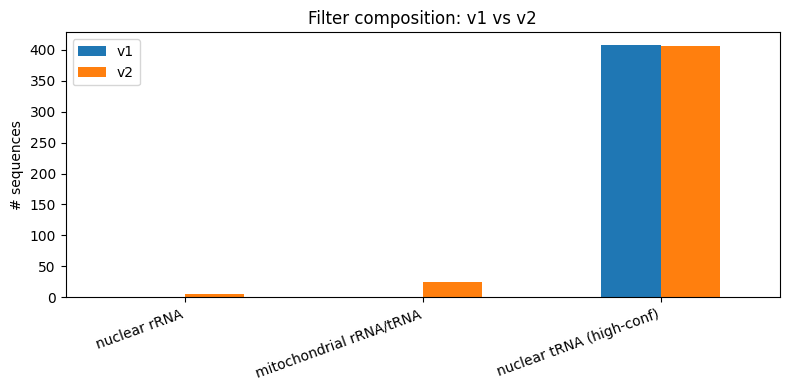

In [4]:
# Coarse classes comparable across versions
COARSE = {
    "ncbi_rRNA": "nuclear rRNA",
    "ncbi_mt": "mitochondrial rRNA/tRNA",
    "gtrnadb_tRNA": "nuclear tRNA (high-conf)",
    "nuclear_rRNA": "nuclear rRNA",
    "nuclear_tRNA": "nuclear tRNA (high-conf)",
}
CLASSES = ["nuclear rRNA", "mitochondrial rRNA/tRNA", "nuclear tRNA (high-conf)"]

def compose(records, catfn):
    c = defaultdict(int)
    for h, _ in records:
        c[COARSE[catfn(h)]] += 1
    return [c.get(k, 0) for k in CLASSES]

comp = pd.DataFrame({"v1": compose(v1, v1_category), "v2": compose(v2, v2_category)}, index=CLASSES)
display(comp)

comp.plot.bar(figsize=(8, 4)); plt.ylabel("# sequences"); plt.title("Filter composition: v1 vs v2");
plt.xticks(rotation=20, ha="right"); plt.tight_layout();

## Sequence-level overlap

Many tRNA records share an identical sequence (same tRNA at different loci), so we compare
the sets of *unique* sequences. v1 and v2 share the nuclear tRNAs; they differ in rRNA
representation - v1's genomic rDNA repeat vs v2's RefSeq rRNA transcripts.

v1: 409 records, 225 unique sequences
v2: 436 records, 253 unique sequences
shared unique sequences: 224
only in v1: 1   only in v2: 29


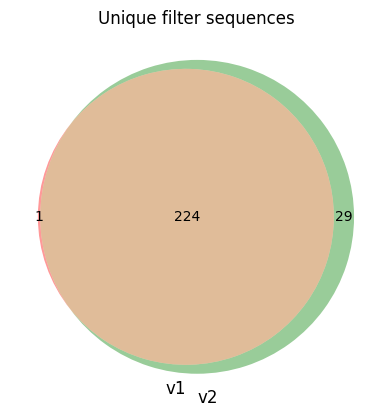

In [5]:
def hashes(records):
    return {hashlib.md5(s.encode()).hexdigest() for _, s in records}

h1, h2 = hashes(v1), hashes(v2)
print(f"v1: {len(v1)} records, {len(h1)} unique sequences")
print(f"v2: {len(v2)} records, {len(h2)} unique sequences")
print(f"shared unique sequences: {len(h1 & h2)}")
print(f"only in v1: {len(h1 - h2)}   only in v2: {len(h2 - h1)}")

venn2([h1, h2], set_labels=("v1", "v2"));
plt.title("Unique filter sequences");

## What changed, by category

In [6]:
def cat_of(records, catfn):
    d = {}
    for h, s in records:
        d.setdefault(hashlib.md5(s.encode()).hexdigest(), COARSE[catfn(h)])
    return d

v1cat = cat_of(v1, v1_category)
v2cat = cat_of(v2, v2_category)

only_v1 = defaultdict(int)
for x in (h1 - h2): only_v1[v1cat[x]] += 1
only_v2 = defaultdict(int)
for x in (h2 - h1): only_v2[v2cat[x]] += 1

print(f"unique sequences only in v1 ({len(h1 - h2)}):")
for k in CLASSES:
    if only_v1.get(k): print(f"  {k}: {only_v1[k]}")
print(f"\nunique sequences only in v2 ({len(h2 - h1)}):")
for k in CLASSES:
    if only_v2.get(k): print(f"  {k}: {only_v2[k]}")

unique sequences only in v1 (1):
  nuclear rRNA: 1

unique sequences only in v2 (29):
  nuclear rRNA: 5
  mitochondrial rRNA/tRNA: 24


## Length distribution

v2 spans tRNAs (~70 nt) up to the 45 kb rDNA repeat, so lengths are shown on a log scale.

v2 length  min/median/max: 59 72 13400


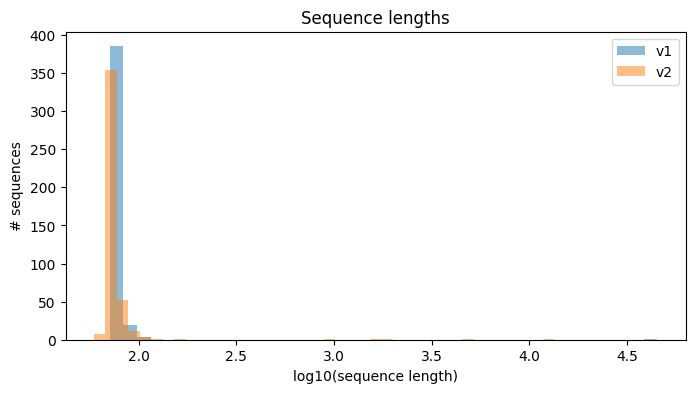

In [7]:
lens_v2 = np.array([len(s) for _, s in v2])
lens_v1 = np.array([len(s) for _, s in v1])

plt.figure(figsize=(8, 4))
plt.hist(np.log10(lens_v1), bins=40, alpha=0.5, label="v1")
plt.hist(np.log10(lens_v2), bins=40, alpha=0.5, label="v2")
plt.xlabel("log10(sequence length)"); plt.ylabel("# sequences"); plt.legend(); plt.title("Sequence lengths");

print("v2 length  min/median/max:", lens_v2.min(), int(np.median(lens_v2)), lens_v2.max())

## Mitochondrial sequences (new in v2)

In [8]:
mt = [(h, s) for h, s in v2 if v2_category(h) == "ncbi_mt"]
print(f"{len(mt)} mitochondrial sequences")
for h, s in mt:
    _, loc, sym = h.split("|")
    print(f"  {sym:9} {len(s):>5} nt   {loc}")

24 mitochondrial sequences
  TrnF         68 nt   NC_005089.1:1-68
  mt-Rnr1     955 nt   NC_005089.1:70-1024
  TrnV         69 nt   NC_005089.1:1025-1093
  mt-Rnr2    1582 nt   NC_005089.1:1094-2675
  TrnL1        75 nt   NC_005089.1:2676-2750
  TrnI         69 nt   NC_005089.1:3706-3774
  TrnQ         71 nt   NC_005089.1:3842-3772
  TrnM         69 nt   NC_005089.1:3845-3913
  TrnW         67 nt   NC_005089.1:4950-5016
  TrnA         69 nt   NC_005089.1:5086-5018
  TrnN         71 nt   NC_005089.1:5159-5089
  TrnC         66 nt   NC_005089.1:5257-5192
  TrnY         67 nt   NC_005089.1:5326-5260
  TrnS1        69 nt   NC_005089.1:6938-6870
  TrnD         70 nt   NC_005089.1:6942-7011
  TrnK         65 nt   NC_005089.1:7700-7764
  TrnG         68 nt   NC_005089.1:9391-9458
  TrnR         68 nt   NC_005089.1:9808-9875
  TrnH         67 nt   NC_005089.1:11546-11612
  TrnS2        59 nt   NC_005089.1:11613-11671
  TrnL2        71 nt   NC_005089.1:11671-11741
  TrnE         69 nt   NC_005

## Summary

In [9]:
summary = f"""
The mouse **v2** filter has **{len(v2)} sequences** ({len(h2)} unique), vs v1's **{len(v1)}**
({len(h1)} unique). They share **{len(h1 & h2)}** unique sequences (the nuclear tRNAs).

v2 replaces v1's genomic rDNA repeat with NCBI RefSeq rRNA transcripts (45S pre-rRNA, 18S,
28S, 5.8S, 5S) and adds the mitochondrial rRNA/tRNA set, so the filter now targets
transcribed rRNA (not the ~32 kb intergenic spacer) plus mitochondrial rRNA/tRNA.
"""
from IPython.display import Markdown, display
display(Markdown(summary))


The mouse **v2** filter has **436 sequences** (253 unique), vs v1's **409**
(225 unique). They share **224** unique sequences (the nuclear tRNAs).

v2 replaces v1's genomic rDNA repeat with NCBI RefSeq rRNA transcripts (45S pre-rRNA, 18S,
28S, 5.8S, 5S) and adds the mitochondrial rRNA/tRNA set, so the filter now targets
transcribed rRNA (not the ~32 kb intergenic spacer) plus mitochondrial rRNA/tRNA.


## Files

* v2 filter: `../mouse_rtRNA.fa.gz` + `../mouse_rtRNA.*.bt2`
* built by `build_filter_v2.py` from `../raw/` (see `../README.md`)
* v1 filter: `../../v1/mouse_rtRNA.*.bt2` (content in `../../v1/mouse_rRNA.fa`)